# Term paper TECH 2

Candidate numbers: XXX, XXX, XXX

## Task 1: Import and prepare the data

### Approach

Because of the size of the files, we read them through functions and keep only the data we need.

In [62]:
import matplotlib.pyplot as plt
import pandas as pd

In [63]:
# Paths to the different files
IPC_FILE = 'data/202608_EPO_IPC.txt'
CPC_FILE = 'data/202608_CPC_Classes.txt'
APP_FILE = 'data/202608_EPO_App_reg.txt'

# Sample period
sample_start = 2000
sample_end = 2019

# Grouping the patents by Y02E code
main_groups = {
    '10': 'Renewable energy',
    '20': 'Efficient combustion',
    '30': 'Nuclear energy',
    '40': 'Efficient power transmission',
    '50': 'Non-fossil fuels',
    '60': 'Storage and hydrogen',
    '70': 'Other energy conversion',
}

# Table 2: first digit after the slash in main group 10 -> technology.
# Digits not listed here (e.g. 0 in 'Y02E 10/00') belong to no technology.
technologies = {
    '1': 'Other renewables',
    '2': 'Other renewables',
    '3': 'Other renewables',
    '4': 'Solar',
    '5': 'Solar',
    '6': 'Solar',
    '7': 'Wind',
}

# All category labels, in a fixed order
main_group_labels = list(main_groups.values())
technology_labels = ['Solar', 'Wind', 'Other renewables']

# Fixed colours, so a group or technology has the same colour in every figure
main_group_colors = {
    'Renewable energy': 'royalblue',
    'Efficient combustion': 'orangered',
    'Nuclear energy': 'mediumseagreen',
    'Efficient power transmission': 'orange',
    'Non-fossil fuels': 'hotpink',
    'Storage and hydrogen': 'green',
    'Other energy conversion': 'slateblue',
}
tech_colors = {
    'Solar': 'orange',
    'Wind': 'royalblue',
    'Other renewables': 'mediumseagreen',
}

In [64]:
def read_sample(path, first_year, last_year):
    """
    Read the patents in the sample period. Avoiding repeated rows.
    """
    ipc = pd.read_csv(path, sep='|', usecols=['appln_id', 'prio_year'])
    in_period = (ipc['prio_year'] >= first_year) & (ipc['prio_year'] <= last_year)
    # The file has one row per IPC code, so a patent can appear on several rows
    return ipc.loc[in_period].drop_duplicates('appln_id').reset_index(drop=True)

In [65]:
def read_y02e_codes(path, sample_ids):
    """
    Read the Y02E codes of the patents in the sample.
    """
    cpc = pd.read_csv(path, sep='|', usecols=['appln_id', 'CPC_Class'])
    is_y02e = cpc['CPC_Class'].str.startswith('Y02E')
    in_sample = cpc['appln_id'].isin(sample_ids)
    return cpc.loc[is_y02e & in_sample].reset_index(drop=True)

In [66]:
def read_applicants(path, sample_ids):
    """
    Read the applicants of the patents in the sample.
    """
    columns = ['appln_id', 'app_name', 'ctry_code', 'app_share']
    
    # Without these two options the country code 'NA' (Namibia) is read as missing
    app = pd.read_csv(
        path, sep='|', usecols=columns, keep_default_na=False, na_values=['']
    )
    # An applicant linked to several regions has several rows that are identical in
    # these four columns, so we drop the duplicates
    app = app.loc[app['appln_id'].isin(sample_ids)].drop_duplicates()
    app = app.reset_index(drop=True)
    # Names that only differ in capitalisation are the same applicant
    app['app_name'] = app['app_name'].str.upper()
    return app

In [67]:
def classify_codes(codes):
    """
    Add the main group (Table 1) and the technology (Table 2) of each Y02E code.
    """

    # Split at the slash:
    parts = codes['CPC_Class'].str.partition('/')
    # Main group: the digits right after 'Y02E'
    main_digits = parts[0].str.partition('Y02E')[2].str.strip()
    # Technology digit: first character after the slash
    tech_digit = parts[2].str.get(0)
    main_group = main_digits.map(main_groups)
    # Only codes in main group 10 belong to a technology
    technology = tech_digit.map(technologies).where(main_digits == '10')
    codes = codes.copy()
    codes['main_group'] = main_group
    codes['technology'] = technology
    return codes

In [68]:
def build_green_categories(codes, sample):
    """
    Make a table with one row per green patent and category.
    """
    main = codes[['appln_id', 'main_group']].rename(columns={'main_group': 'category'})
    tech = codes[['appln_id', 'technology']].rename(columns={'technology': 'category'})
    tech = tech.dropna()  # codes without a technology
    # A patent counts once in each category:
    long = pd.concat([main, tech]).drop_duplicates()
    return long.merge(sample[['appln_id', 'prio_year']], on='appln_id', how='left')

### Read the data

The sample's `appln_id`s are passed on to the two other readers, so that they only return rows for patents in the sample.

In [69]:
# The sample: one row per EPO application with priority year between 2000 and 2019
sample = read_sample(IPC_FILE, sample_start, sample_end)

# All Y02E codes of patents in the sample, with main group and technology
green_codes = read_y02e_codes(CPC_FILE, sample['appln_id'])
green_codes = classify_codes(green_codes)

# A patent is green if it has at least one Y02E code
sample['green'] = sample['appln_id'].isin(green_codes['appln_id'])

# One row per green patent and category, with the priority year
green_cat = build_green_categories(green_codes, sample)

# The applicants of all patents in the sample
applicants = read_applicants(APP_FILE, sample['appln_id'])

green_cat.head()

,appln_id,category,prio_year
0,91,Nuclear energy,2004
1,103,Efficient combustion,2005
2,146,Renewable energy,2006
3,204,Efficient combustion,2008
4,240,Renewable energy,2007


### Checkpoints

The three checkpoints from the task are compared with our numbers. The `Match` column shows whether each of them
matches.

In [70]:
checkpoints = pd.DataFrame(
    {
        'Our result': [
            len(sample),
            sample['green'].sum(),
            round(applicants['app_share'].sum()),
        ],
        'Expected': [2_835_599, 114_924, 2_835_140],
    },
    index=[
        'EPO patent applications in the sample',
        'Green energy patents in the sample',
        'Sum of app_share (rounded)',
    ],
)
checkpoints['Match'] = checkpoints['Our result'] == checkpoints['Expected']
checkpoints

,Our result,Expected,Match
EPO patent applications in the sample,2835599,2835599,True
Green energy patents in the sample,114924,114924,True
Sum of app_share (rounded),2835140,2835140,True


### Overview of the data structure

* Y02E codes per green patent: we count *distinct* codes per patent, since a code listed twice for the same patent
  does not add information.
* Green patents in more than one main group: `green_cat` already has one row per patent and main group, so we
  count how often each patent appears among the main-group rows.
* Patents with applicants in more than one country: the number of distinct `ctry_code`s per patent (`NA` is read as
  Namibia, not as a missing value).

In [71]:
n_green = sample['green'].sum()

# Average number of distinct Y02E codes per green patent
n_distinct_codes = len(green_codes.drop_duplicates(['appln_id', 'CPC_Class']))
avg_codes = n_distinct_codes / n_green

# Green patents that belong to more than one main group
is_main_group = green_cat['category'].isin(main_group_labels)
n_multi_group = (green_cat.loc[is_main_group, 'appln_id'].value_counts() > 1).sum()

# Patents in the sample with applicants in more than one country
countries = applicants[['appln_id', 'ctry_code']].drop_duplicates()
n_multi_country = (countries['appln_id'].value_counts() > 1).sum()

print(f'Average number of Y02E codes per green patent: {avg_codes:.2f}')
print(f'Green patents in more than one main group: {n_multi_group:,}')
print(f'Patents with applicants in more than one country: {n_multi_country:,}')

Average number of Y02E codes per green patent: 1.23
Green patents in more than one main group: 4,359
Patents with applicants in more than one country: 58,955


### Free memory

The checkpoints are the only place where we need the applicants of *all* patents in the sample. Task 5 only looks at
green patents, so we keep only their applicants (about 4% of the rows).
The code-level table `green_codes` is not needed after Task 1, because `green_cat` holds everything the later tasks
use.

In [72]:
applicants = applicants.loc[applicants['appln_id'].isin(green_cat['appln_id'])]
del green_codes, is_main_group

# Number of rows in the DataFrames that Tasks 2-5 work with
pd.Series(
    {
        'sample': len(sample),
        'green_cat': len(green_cat),
        'applicants': len(applicants),
    },
    name='Rows',
).to_frame()

,Rows
sample,2835599
green_cat,162166
applicants,126097


### Results of Task 1

The data files are large, so each of the three files is read inside its own function, which keeps only the rows and columns we need. Two more functions classify the Y02E codes and build the table of green patents per category that Tasks 2-5 use.

All three checkpoints match: the sample has 2,835,599 patents, 114,924 of them are green energy patents, and the sum of app_share is 2,835,140.

An applicant linked to several regions appears on several rows that are identical in the four columns we read (appln_id, app_name, ctry_code, app_share). We remove these duplicate rows before counting.

Overview of the data:

A green patent has 1.23 distinct Y02E codes on average. Most green patents have only one code, but counting codes instead of patents would still overstate the numbers a little.
4,359 green patents (3.8%) belong to more than one main group. In Task 3, these patents count once in each main group, so the counts add up to slightly more than the number of green patents.
58,955 patents (2.1%) have applicants in more than one country. Counting whole patents per country would count these several times, which is why fractional counting matters in Task 5.

After the checkpoints, we keep only the applicants of green patents, so the data used in Tasks 2-5 are much smaller.

## Task 2: Has green energy patenting slumped?

We use groupby to find the amount of green patents and total patents per year.
Summing the True/False column 'green' counts the amount of green patents and the group size counts all patents.

In [73]:
# Create a dataframe with the green and total patents for every year
yearly = sample.groupby('prio_year').agg(
    green=('green', 'sum'),
    total=('appln_id', 'size'),
)
# The amount of green patents / total amount of patents * 100 = share of green patents
yearly['green_share'] = yearly['green'] / yearly['total'] * 100
# Give new names to the columns
yearly.columns = ['Green energy patents', 'All patents', 'Green share (%)']
# Give name to the index values (the priority years)
yearly.index.name = 'Priority year'
yearly.round(2)

,Green energy patents,All patents,Green share (%)
Priority year,,,
2000,2295,116789,1.97
2001,2506,115161,2.18
2002,2507,118892,2.11
2003,2863,124660,2.30
2004,3132,132552,2.36
2005,3656,137653,2.66
2006,4261,137191,3.11
2007,5082,135529,3.75
2008,5859,130726,4.48


Looking at the table we see that the amount of green patenting falls after 2011, so we find where the slump starts and ends.
To find where the slump starts, we find the peak by finding the first year that the amount of green patenting falls, then the peak is the year before.
The end of the slump will be the year before the first time that the amount grows again after the start of the slump.

In [74]:
# shorter name for the column with amount of green patents
green = yearly['Green energy patents']

# Start of the slump is the year before the first fall in green patenting
# break stops the loop at the first year found
for year in green.index[1:]:
    if green.loc[year] < green.loc[year - 1]:
        slump_start = year - 1
        break

# End of the slump is the year before the amount of green patenting rises again
# break stops the loop at the first year found
for year in green.loc[slump_start + 1 :].index:
    if green.loc[year] > green.loc[year - 1]:
        slump_end = year - 1
        break

# Level and change (in %) of each column between key years
key_years = [sample_start, slump_start, slump_end, sample_end]
key = yearly.loc[key_years].T
key.columns = [
    f'{sample_start}',
    f'Peak ({slump_start})',
    f'Trough ({slump_end})',
    f'{sample_end}',
]
key['Change peak to trough (%)'] = (key.iloc[:, 2] / key.iloc[:, 1] - 1) * 100
key['Change trough to 2019 (%)'] = (key.iloc[:, 3] / key.iloc[:, 2] - 1) * 100
key.round(1)

,2000,Peak (2011),Trough (2015),2019,Change peak to trough (%),Change trough to 2019 (%)
Green energy patents,2295.0,8251.0,6508.0,8660.0,-21.1,33.1
All patents,116789.0,143392.0,154489.0,173460.0,7.7,12.3
Green share (%),2.0,5.8,4.2,5.0,-26.8,18.5


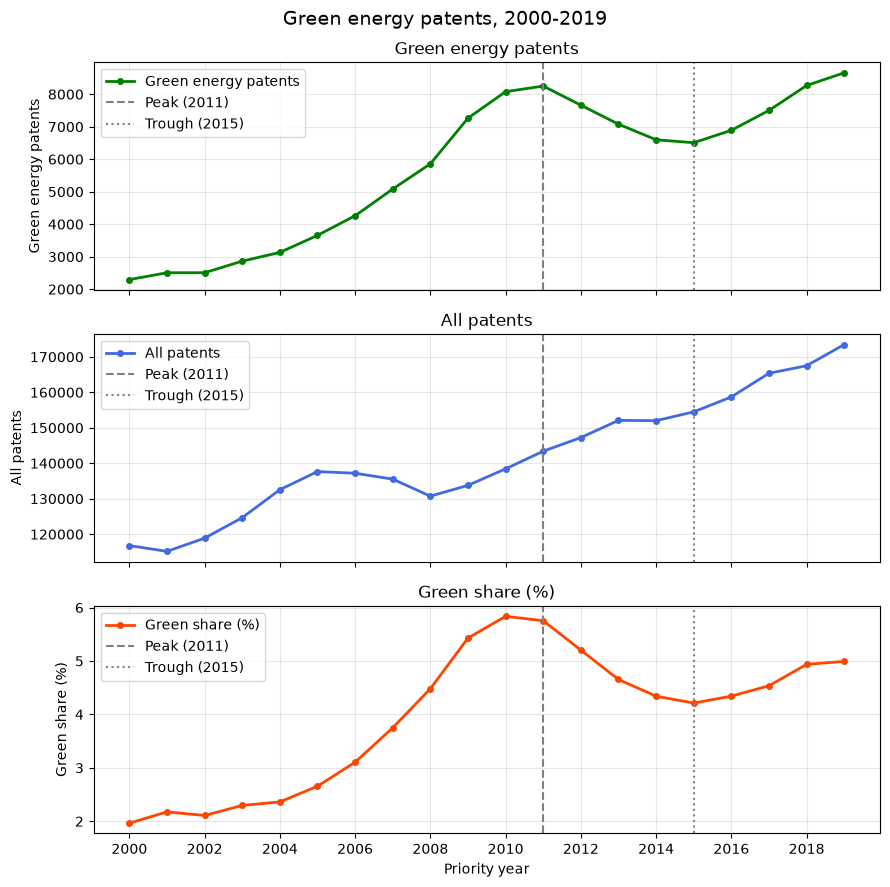

In [75]:
# Create a subplot with three panels stacked vertically, making them share x-axis
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
panel_colors = ['green', 'royalblue', 'orangered']

# Create a plot for each column in the dataframe
for i, column in enumerate(yearly.columns):
    ax = axes[i]
    ax.plot(
        yearly.index,
        yearly[column],
        color=panel_colors[i],
        lw=2,
        marker='o',
        ms=4,
        label=column,
    )
    # Mark the start and end of slump in every panel
    ax.axvline(slump_start, color='grey', ls='--', label=f'Peak ({slump_start})')
    ax.axvline(slump_end, color='grey', ls=':', label=f'Trough ({slump_end})')
    ax.set_ylabel(column)
    ax.set_title(column)
    ax.grid(alpha=0.3)
    ax.legend(loc='upper left')

# Set xlabel and ticks at the bottom panel, and a title for the whole figure
axes[-1].set_xlabel('Priority year')
axes[-1].set_xticks(range(sample_start, sample_end + 1, 2))
fig.suptitle('Green energy patents, 2000-2019', fontsize=14)
fig.tight_layout()
plt.show()

### Answers to Task 2

The amount of green patenting increased a lot during the 2000s. It grew from 2,295 patents in 2000 to 8,251 in 2011. It then falls from 2011 to 2015, before increasing again until the end of the sample period in 2019. The total amount of patents increases until 2005, decreases slightly until 2008, before increasing again for the remainder of the sample period. 

Yes, there is a slump. The slump starts at the peak in 2011 when there was 8,251 green patents and falls until 2015 when there were 6,508 green patents. The slump is also apparent in the green share of patents, falling from 5.8% to 4.2% in the same period. From the end of the slump until the end of the sample period the amount of green patents rises again.

The slump is specific to green energy. During the slump of green patents, the total amount of all patents actually grew by 7.7%. The total amount of patents also falls during 2005-2008, while the amount of green patents grows, this leads to the share of green patents growing.

## Task 3: How has the technology mix changed?

The five-year periods are made with integer division. Since "green_cat" has one row per patent and main group, a patent in two main groups counts once in each. Therefore the shares are shares of the main-group counts in a period, which add up to 100%. 

In [76]:
# Only the main-group rows (Table 1) of green_cat
main = green_cat.loc[green_cat['category'].isin(main_group_labels)]

# Five-year periods: for example 2007 // 5 * 5 = 2005, labelled '2005-2009'
start = main['prio_year'] // 5 * 5
period = start.astype(str) + '-' + (start + 4).astype(str)
period.name = 'Period'

# Counts per period and main group, in the order of Table 1
mix_counts = pd.crosstab(period, main['category'])[main_group_labels]

# Each main group's share of the counts in a period, in percent
shares = pd.crosstab(period, main['category'], normalize='index') * 100
mix_shares = shares[main_group_labels]

mix_counts

category,Renewable energy,Efficient combustion,Nuclear energy,Efficient power transmission,Non-fossil fuels,Storage and hydrogen,Other energy conversion
Period,,,,,,,
2000-2004,3136,705,499,287,764,8243,106
2005-2009,10676,1279,738,475,2554,11180,356
2010-2014,15080,1691,1145,875,2910,17426,604
2015-2019,11797,934,1063,903,1792,22478,559


In [77]:
# Shares in percent. The last column shows that every period adds up to 100
shares_table = mix_shares.copy()
shares_table['Total'] = shares_table.sum(axis=1)
shares_table.round(1)

category,Renewable energy,Efficient combustion,Nuclear energy,Efficient power transmission,Non-fossil fuels,Storage and hydrogen,Other energy conversion,Total
Period,,,,,,,,
2000-2004,22.8,5.1,3.6,2.1,5.6,60.0,0.8,100.0
2005-2009,39.2,4.7,2.7,1.7,9.4,41.0,1.3,100.0
2010-2014,38.0,4.3,2.9,2.2,7.3,43.9,1.5,100.0
2015-2019,29.8,2.4,2.7,2.3,4.5,56.9,1.4,100.0


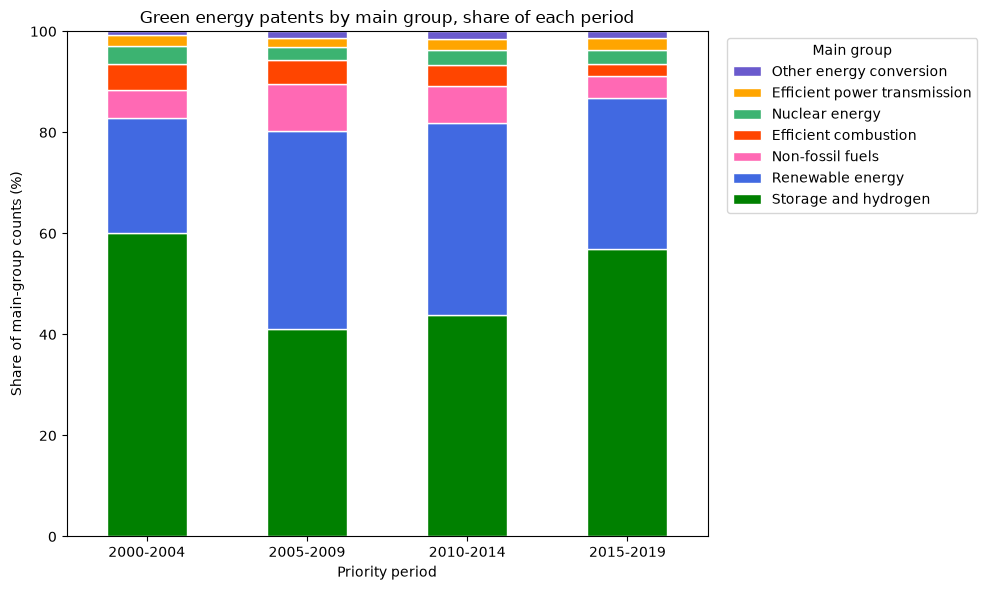

In [78]:
# Creating the stacks graph for the green energy patent share for the different periods, with matplotlib.
fig, ax = plt.subplots(figsize=(10, 6))

# We wanted it to sort the pillars by size for the visual aspect
order = mix_shares.mean().sort_values(ascending=False).index
mix_shares[order].plot.bar(
    stacked=True, color=main_group_colors, edgecolor='white', rot=0, ax=ax,
)

ax.set_title('Green energy patents by main group, share of each period')
ax.set_xlabel('Priority period')
ax.set_ylabel('Share of main-group counts (%)')
ax.set_ylim(0, 100)

# Legend outside the plot so it does not cover the bars, in the same order as the stack
ax.legend(reverse=True, title='Main group', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()

### Answers to Task 3

#### Which main groups make up most of green energy patenting?

Two main groups make up most of green energy patenting is storage and hydrogen and
renewable energy. Together they account for 80–87% of the main-group counts in every period. Non-fossil fuels is the third largest group, with 4.5–9.4%. The other four groups are small, with at most about 5% each.


##### How has the mix changed?

Renewable energy had the biggest increase. Its share rose from 22.8% in 2000–2004 to 39.2% in 2005–2009 and stayed high in 2010–2014 (38.0%). Its count grew almost fivefold, from 3,136 to 15,080, but in 2015–2019 it dropped down to 11,797 patents and a share of 29.8%.
Storage and hydrogen had a falling share during the green energy boom (from 60.0% to 41.0%), because the other groups grew faster. Still, its count grew in every period, from 8 243 to 22 478, and its share was back at 56.9% in 2015–2019.
Non-fossil fuels followed the same increase and following decrease pattern as renewables. Its share peaked at 9.4% in 2005–2009, and its count fell from 2,910 to 1,792 between the last two periods. Efficient combustion shrank from 5.1% to 2.4%.

##### Relation to the slump in Task 2.

The slump comes from the technologies that drove the boom. From 2010–2014 to 2015–2019, renewable energy lost 3,283 patents and non-fossil fuels lost 1,118. Storage and hydrogen kept growing and
added 5,052 patents in the same comparison, which is why total green patenting recovered after 2015. In short, the mix
shifted from energy generation like solar, wind and biofuels towards storage and hydrogen such as batteries and fuel
cells.

## Task 4: Wind versus solar

Each patent appears only once per technology in green_cat, so the yearly counts per technology are the number of rows with each combination of year and technology. This is the same as the number of patents.

In [79]:
# tech filters green_cat by the three technologies
# tech_year counts each combination of a year and a technology
# the final tech_year dataframe shows the number of patents in each technology in each year
tech = green_cat.loc[green_cat['category'].isin(technology_labels)]
tech_year = pd.crosstab(tech['prio_year'], tech['category'])
tech_year = tech_year[technology_labels]
tech_year.index.name = 'Priority year'
tech_year.head()

category,Solar,Wind,Other renewables
Priority year,,,
2000,306,116,34
2001,334,182,52
2002,328,151,54
2003,467,222,74
2004,548,244,109


In [80]:
# create dataframe that shows peak year, number of patents in peak year, number of patents in the last year and change from peak to sample end for each technology
peaks = pd.DataFrame(
    {
        'Peak year': tech_year.idxmax(),
        'Patents in peak year': tech_year.max(),
        f'Patents in {sample_end}': tech_year.loc[sample_end],
    }
)
peaks[f'Change peak to {sample_end} (%)'] = (
    (peaks[f'Patents in {sample_end}'] / peaks['Patents in peak year'] - 1) * 100
).round(1)
# sorts the values in descending order
peaks = peaks.sort_values('Patents in peak year', ascending=False)
# sets index name to technology
peaks.index.name = 'Technology'
peaks

,Peak year,Patents in peak year,Patents in 2019,Change peak to 2019 (%)
Technology,,,,
Solar,2010,2323,1093,-52.9
Wind,2011,1188,1024,-13.8
Other renewables,2011,296,172,-41.9


To find out whether a technology recovered after a potential collapse, we need to find out if it rises again after falling. To do this we find the lowest point after the peak and see if it rises again until 2019.

In [81]:
# for each technology we locate the peak and trough year
# we then add the technology, the trough and the patents in the trough year to a new dataframe
# for each technology, compute the change from trough to sample end
rows = []
for technology in peaks.index:
    peak_year = peaks.loc[technology, 'Peak year']
    after_peak = tech_year.loc[peak_year:, technology]
    rows.append(
        {
            'Technology': technology,
            'Trough year after peak': after_peak.idxmin(),
            'Patents in trough year': after_peak.min(),
        }
    )
recovery = pd.DataFrame(rows).set_index('Technology')
recovery[f'Change trough to {sample_end} (%)'] = (
    (peaks[f'Patents in {sample_end}'] / recovery['Patents in trough year'] - 1) * 100
).round(1)
recovery.index.name = 'Technology'
recovery

,Trough year after peak,Patents in trough year,Change trough to 2019 (%)
Technology,,,
Solar,2019,1093,0.0
Wind,2015,782,30.9
Other renewables,2018,167,3.0


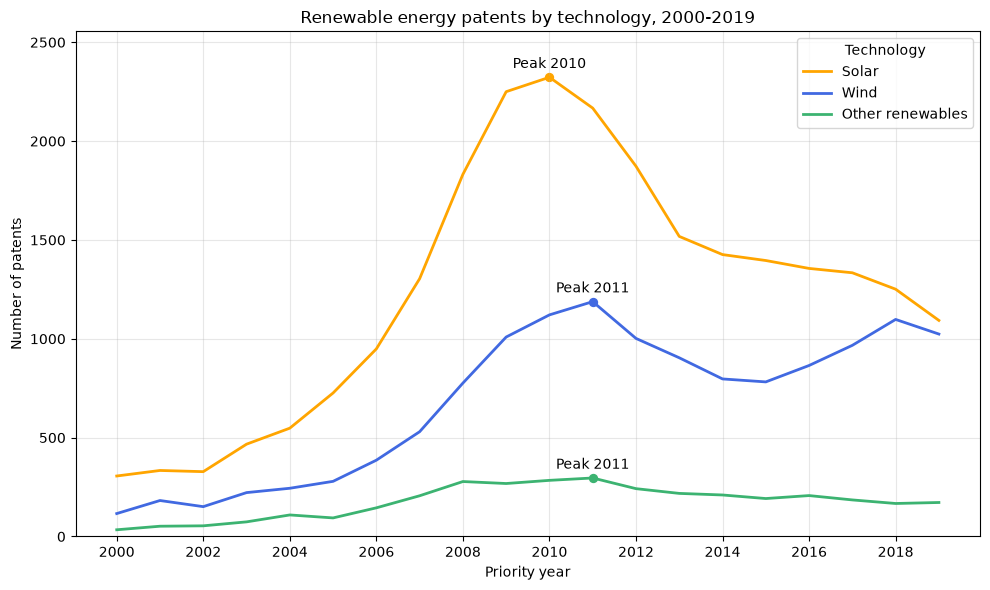

In [82]:
fig, ax = plt.subplots(figsize=(10, 6))

# we plot each technology against the years
for technology in technology_labels:
    color = tech_colors[technology]
    ax.plot(tech_year.index, tech_year[technology], color=color, lw=2, label=technology)
    # Mark the peak with a point and label it with the peak year
    peak_year = peaks.loc[technology, 'Peak year']
    peak_count = peaks.loc[technology, 'Patents in peak year']
    ax.scatter(peak_year, peak_count, color=color, s=60, edgecolor='white')
    ax.text(peak_year, peak_count + 30, f'Peak {peak_year}', ha='center', va='bottom')

ax.set_title('Renewable energy patents by technology, 2000-2019')
ax.set_xlabel('Priority year')
ax.set_ylabel('Number of patents')
ax.set_xticks(range(sample_start, sample_end + 1, 2))
ax.set_ylim(0, peaks['Patents in peak year'].max() * 1.1)
ax.grid(alpha=0.3)
ax.legend(title='Technology')
fig.tight_layout()
plt.show()

### Answers to Task 4

**Which technologies collapsed after their peak?**

Solar has the highest peak, but also the largest collapse.
The peak was in 2010 when there were 2,323 patents, before it fell until the end of the sample period, 2019, when it there were 1,093 patents. That is a decline of 52.9% from the peak. 2019 is the lowest point after the peak, meaning that solar energy patents collapsed after the peak and never recovered.

Patents for wind energy have a peak in 2011, when there was 1,188 patents. After this, the number of patents falls for a few years until 2015, the lowest year after the peak. After 2015 the number of patents rises again, meaning that wind patents recovered after falling from the peak. In 2019, wind is 13.8% down from its peak, but 30.9% up from its trough.

Other renewables has far fewer patents throughout the whole period. It has a small peak in 2011. After the peak it falls until 2018, before increasing slightly with 3% until 2019. That amounts to a fall of 41.9% from the peak until 2019.

Solar technology collapses after its peak in 2010. Wind was the only technology to substantially recover after falling from its peak. Other renewables fall after its peak, but at a slower rate, and in the last year it increased with 3%

## Task 5: Who drives green energy innovation?

We merge the applicants with `green_cat`. Because `green_cat` has exactly one row per patent and category, each
applicant appears once per category of its patent, and summing `app_share` gives the fractional count without double
counting. The few green patents without applicant data drop out of the merge.

In [83]:
# One row per applicant and category of its patent
green_app = applicants.merge(green_cat, on='appln_id')

In [84]:
# The column to group by for countries and for applicants
BY_COLUMNS = {'country': 'ctry_code', 'applicant': 'app_name'}


def top_n(data, category, by, start=sample_start, end=sample_end, n=10):
    """
    Return the n countries or applicants with the most patents in a category.

    Patents are counted fractionally: a country or applicant gets the sum of its
    app_share over the patents in the category and period.

    Parameters
    ----------
    data : DataFrame
        Applicants merged with green_cat.
    category : str
        A label from Table 1 (e.g. 'Storage and hydrogen') or Table 2 (e.g. 'Wind').
    by : str
        'country' or 'applicant'.
    start, end : int
        First and last priority year of the period.
    n : int
        Number of countries or applicants to return.

    Returns
    -------
    top : DataFrame
        The top n, largest first, in the column patents. For applicants, the
        column country gives the applicant's most common country.
    """
    in_period = (data['prio_year'] >= start) & (data['prio_year'] <= end)
    selected = data.loc[(data['category'] == category) & in_period]
    patents = selected.groupby(BY_COLUMNS[by])['app_share'].sum()
    top = patents.sort_values(ascending=False, kind='stable').head(n)
    top = top.to_frame('patents')
    if by == 'applicant':
        # Most common country of each top applicant
        top_rows = selected.loc[selected['app_name'].isin(top.index)]
        top['country'] = top_rows.groupby('app_name')['ctry_code'].agg(
            lambda countries: countries.value_counts().idxmax()
        )
    top.index.name = by
    return top

In [85]:
def plot_top_bars(ax, top, title, color, xlabel='Patents (fractional count)'):
    """
    Draw a horizontal bar chart of a top-n table, with the largest at the top.

    Parameters
    ----------
    ax : Axes
        The panel to draw on.
    top : DataFrame
        Output of top_n. If it has a country column, the country is added to
        each label.
    title : str
        Panel title.
    color : str
        Bar colour.
    xlabel : str
        Label of the x-axis.
    """
    # barh draws the first row at the bottom, so sort from smallest to largest
    top = top.sort_values('patents')
    # Shorten long applicant names so the bars keep enough room
    labels = top.index.str[:40]
    if 'country' in top:
        labels = labels + ' (' + top['country'].astype(str) + ')'
    ax.barh(labels, top['patents'], color=color, label=xlabel)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis='x', alpha=0.3)
    ax.legend(loc='lower right')

### Countries in renewable energy

In [86]:
country_periods = [(2005, 2009), (2015, 2019)]
top_countries = {
    f'{start}-{end}': top_n(green_app, 'Renewable energy', 'country', start, end)
    for start, end in country_periods
}

# The two top-10 lists side by side
pd.concat(
    [top.reset_index() for top in top_countries.values()],
    axis=1,
    keys=top_countries.keys(),
).round(1)

2005-2009         2015-2019        
    country patents   country patents
0        US  2628.1        DE  2133.7
1        DE  2216.3        US  1750.3
2        JP  1530.5        DK  1501.3
3        DK   493.5        JP  1114.1
4        KR   450.7        KR   886.0
5        FR   424.7        CN   836.0
6        ES   342.1        FR   643.9
7        GB   331.3        ES   383.0
8        IT   280.5        GB   359.0
9        CH   257.8        NL   310.8

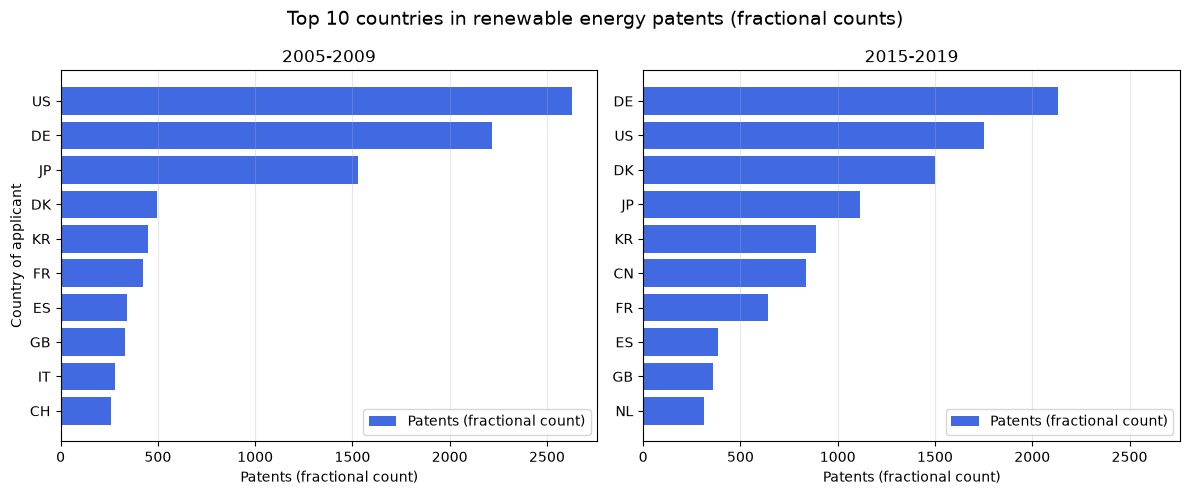

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

# sharex=True gives both panels the same x-axis scale, so they can be compared
for i, period_label in enumerate(top_countries):
    top = top_countries[period_label]
    plot_top_bars(axes[i], top, period_label, main_group_colors['Renewable energy'])
axes[0].set_ylabel('Country of applicant')

fig.suptitle(
    'Top 10 countries in renewable energy patents (fractional counts)', fontsize=14
)
fig.tight_layout()
plt.show()

### Applicants in solar and wind

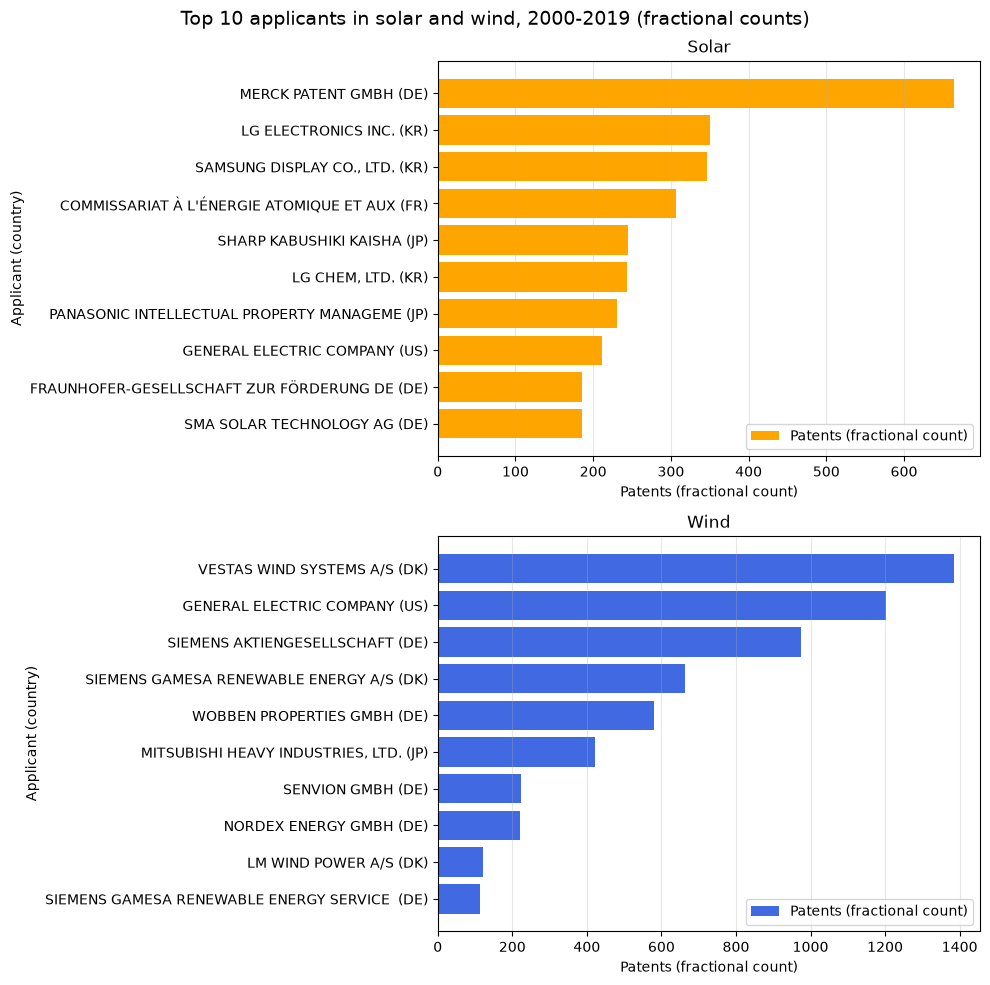

In [88]:
top_applicants = {
    technology: top_n(green_app, technology, 'applicant')
    for technology in ['Solar', 'Wind']
}

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

for i, technology in enumerate(top_applicants):
    plot_top_bars(
        axes[i], top_applicants[technology], technology, tech_colors[technology]
    )
    axes[i].set_ylabel('Applicant (country)')

fig.suptitle(
    f'Top 10 applicants in solar and wind, {sample_start}-{sample_end} (fractional counts)',
    fontsize=14,
)
fig.tight_layout()
plt.show()

To see whether the applicants explain the changes among countries, we also look at the top applicants in renewable
energy in the same two periods as the country figure.

In [89]:
pd.concat(
    [
        top_n(green_app, 'Renewable energy', 'applicant', start, end).reset_index()
        for start, end in country_periods
    ],
    axis=1,
    keys=top_countries.keys(),
).round(1)

2005-2009                  \
                                           applicant patents country   
0                           GENERAL ELECTRIC COMPANY   492.0      US   
1                            VESTAS WIND SYSTEMS A/S   317.0      DK   
2                         SIEMENS AKTIENGESELLSCHAFT   203.5      DE   
3                             SHARP KABUSHIKI KAISHA   149.7      JP   
4                  MITSUBISHI HEAVY INDUSTRIES, LTD.   142.5      JP   
5                                  MERCK PATENT GMBH   130.0      DE   
6               E. I. DU PONT DE NEMOURS AND COMPANY    87.5      US   
7                           SANYO ELECTRIC CO., LTD.    86.0      JP   
8  FRAUNHOFER-GESELLSCHAFT ZUR FÖRDERUNG DER ANGE...    85.2      DE   
9                                LG ELECTRONICS INC.    83.0      KR   

                                           2015-2019                  
                                           applicant patents country  
0                            VESTAS WIND SYSTEMS A/S   588.8      DK  
1                SIEMENS GAMESA RENEWABLE ENERGY A/S   583.5      DK  
2                           GENERAL ELECTRIC COMPANY   341.0      US  
3                             WOBBEN PROPERTIES GMBH   333.0      DE  
4                          SAMSUNG DISPLAY CO., LTD.   277.3      KR  
5                                  MERCK PATENT GMBH   170.0      DE  
6                         SIEMENS AKTIENGESELLSCHAFT   132.5      DE  
7                                LG ELECTRONICS INC.   123.0      KR  
8  COMMISSARIAT À L'ÉNERGIE ATOMIQUE ET AUX ÉNERG...    97.1      FR  
9           GENERAL ELECTRIC RENOVABLES ESPAÑA, S.L.    95.0      ES

### Answers to Task 5

**Which countries lead, and how has this changed?** In 2005–2009, the **US** led renewable energy patenting (2,628
patents), ahead of **Germany** (2,216) and **Japan** (1,530). No other country had more than 500. In 2015–2019,
**Germany** led (2,134, almost unchanged at −4%), while the US fell by 33% to 1,750 and Japan by 27% to 1,114.
**Denmark** tripled its count, from 494 to 1,501, and moved from 4th to 3rd place. **South Korea** almost doubled
(451 → 886), and **China** entered the top 10 in 6th place (836). Italy and Switzerland dropped out of the top 10, and
the Netherlands came in.

**Which organisations dominate solar and wind?**

* **Solar** is dominated by large **electronics and chemicals conglomerates** from East Asia and Germany: Merck Patent
  (DE, by far the largest with 664 patents, materials for solar cells), LG Electronics, Samsung Display and LG Chem
  (KR), Sharp and Panasonic (JP), and General Electric (US). Two **public research institutes** are also in the top 10:
  CEA (FR) and Fraunhofer (DE). SMA Solar Technology (DE, inverters) is the only solar specialist. Solar is
  fragmented: the top 10 hold only about 12% of all solar patents.
* **Wind** is dominated by **specialised wind-turbine makers**, mostly from Denmark and Germany: Vestas (DK, 1,385),
  Siemens Gamesa (DK and DE), Wobben Properties (DE, which holds the patents of the turbine maker Enercon), Senvion,
  Nordex (DE) and the blade maker LM Wind Power (DK). The rest of the top 10 are **industrial conglomerates** with a
  wind business: General Electric (US), Siemens (DE) and Mitsubishi Heavy Industries (JP). No research institutes are
  in the top 10. Wind is concentrated: the top 10 hold about 43% of all wind patents.

**Do the applicants explain the changes among countries?** Largely yes, as the table of top renewable energy applicants
by period shows.

* **Denmark's rise** comes from the wind specialists. Vestas grew from 317 to 589 patents, and Siemens Gamesa Renewable
  Energy A/S, Siemens' Danish wind business, became the second largest applicant (584). At the same time, Siemens AG in
  Germany fell from 204 to 133, so part of Siemens' wind patenting moved from a German to a Danish applicant.
* **The US decline** follows General Electric, the largest applicant in 2005–2009 (492), which fell to 341. Part of
  GE's wind patents are now filed by its Spanish subsidiary (GE Renovables España, 95), which counts for Spain.
* **Japan's decline** follows the solar collapse. Sharp, Sanyo and Mitsubishi Heavy Industries are in the top 10 in
  2005–2009 but not in 2015–2019. **Korea's rise** follows Samsung Display and LG Electronics.
* **Germany held its position** because wind (Wobben/Enercon, Siemens) and solar materials (Merck) partly offset each
  other.

Because solar collapsed while wind recovered (Task 4), the countries with wind champions (Denmark, Germany) gained
relative to those whose renewable patenting relied on solar electronics (Japan, the US).

## Task 6 — Use of online resources

We used a range of online resources and tools for this assignment. In all the tasks we followed a three-step system. First, we tried to solve as much of the task as possible ourselves; then we used pandas.pydata.org and geeksforgeeks.org when we got stuck. When we weren't sure which method to use, we asked Claude Code to suggest methods and functions. 

We have focused on learning, therefore, we made sure to understand every piece of code in the notebook. In this way we learned the new methods that Claude recommended to us. 

These are the methods we got from Claude: 
.drop_duplicates(): cells 5, 7, 9 and 15 (twice in 15)
.str.startswith(): cell 6
.str.upper(): cell 7
.str[:40]: cell 42
.idxmin(): cell 34
pd.DataFrame(rows): cell 34
.index.name = ...: cells 20, 31, 32, 34 and 39
Named aggregation, .agg(new_name=('column', 'operation')): cells 20 and 38
lambda inside .agg(): cell 39
pd.crosstab(): cell 31
.iloc[] and T combined: cell 22 (We didn’t think of combining .iloc and T even though both have been mentioned in class)
